# Stage 2: history findings

A walk-through of findings 1, 2, 7 and 8 for **Wall Street in Charts**. Every number here comes from `wallstreet/findings.py`, the same code that writes the findings pages, so the notebook and the report always agree.

Run `python data/fetch.py` first if `data/processed/` is empty.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import SVG, display

from wallstreet import charts as C
from wallstreet import findings as F

pd.options.display.float_format = "{:,.2f}".format

## 1. Who grew biggest?

Revenue and profit in 2015 and 2025 ($bn), how many times bigger each is, and the yearly growth rate of profit.

In [2]:
g = F.growth_table()
table = pd.DataFrame(
    {
        "Revenue 2015": g["revenue_first"] / 1e9,
        "Revenue 2025": g["revenue_last"] / 1e9,
        "Profit 2015": g["profit_first"] / 1e9,
        "Profit 2025": g["profit_last"] / 1e9,
        "Profit ×": g["profit_multiple"],
        "Profit growth a year": g["profit_cagr"] * 100,
        "Margin 2025 %": g["margin_last"] * 100,
    }
)
table.index = [F.short_name(f) for f in table.index]
table.sort_values("Profit ×", ascending=False)

,Revenue 2015,Revenue 2025,Profit 2015,Profit 2025,Profit ×,Profit growth a year,Margin 2025 %
Goldman,33.82,58.28,6.08,17.18,2.82,10.94,29.47
Morgan Stanley,35.16,70.64,6.13,16.86,2.75,10.65,23.87
JPMorgan,93.54,182.45,24.44,57.05,2.33,8.85,31.27
BlackRock,11.40,24.22,3.35,5.55,1.66,5.20,22.93
State Street,10.36,13.94,1.98,2.94,1.49,4.05,21.12


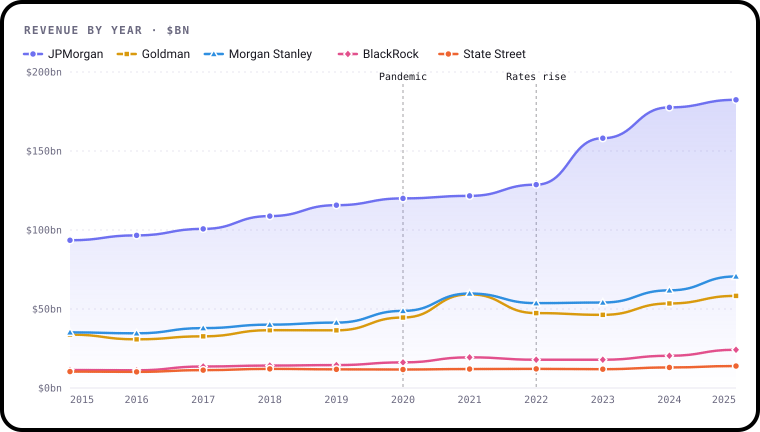

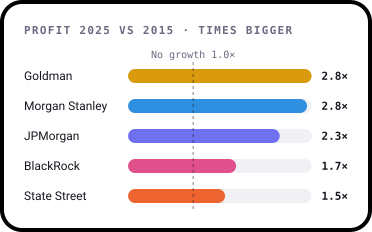

In [3]:
display(SVG(str(C.revenue_line("light"))))
display(SVG(str(C.profit_growth_bars("light"))))

**Reading it:** JPMorgan is the giant, but Goldman and Morgan Stanley grew profit fastest from a smaller base. BlackRock's revenue grew faster than its profit, so its margin narrowed.

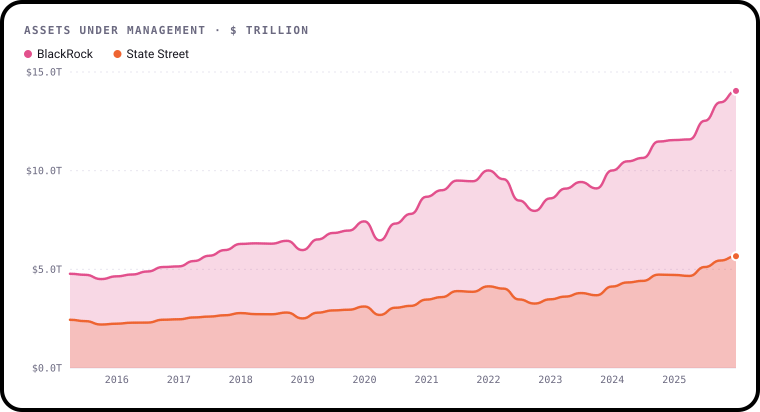

,Vanguard AUM ($T)
as_of,
2017-12-31,4.90
2019-03-31,5.40
2019-11-30,6.00
2020-10-31,6.30
2021-11-30,8.20
2021-12-31,8.50
2022-12-31,7.20
2023-09-30,7.80
2023-12-31,8.60


In [4]:
display(SVG(str(C.aum_area("light"))))
F.vanguard_aum().to_frame("Vanguard AUM ($T)")

## 2. Where do the banks make money?

Share of each bank's 2025 revenue by kind of business.

In [5]:
shares = pd.DataFrame({F.short_name(b): F.segment_share(b, 2025) * 100 for b in F.BANKS}).T
shares.columns = [F.BUCKETS[c] for c in shares.columns]
shares.round(1)

,Banking and lending,Trading and dealmaking,Wealth and asset management
JPMorgan,42.60,43.90,13.50
Goldman,0.30,71.10,28.60
Morgan Stanley,NaN,46.40,53.60


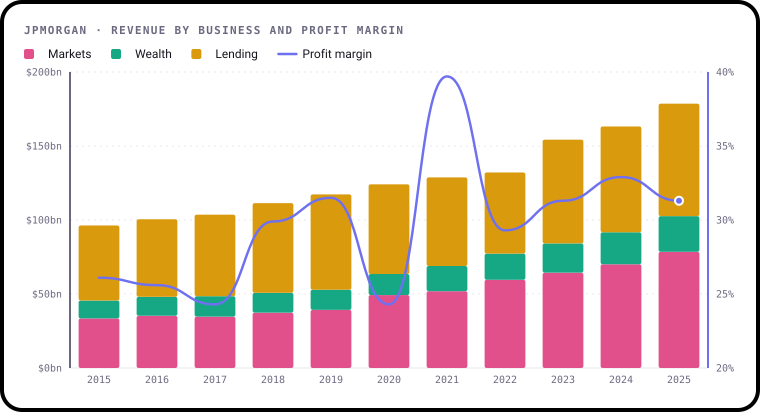

In [6]:
display(SVG(str(C.segment_combos("light")["f2-segments-jpmorgan"])))

JPMorgan regrouped its segments in 2022 (commercial banking moved into the investment bank), so the 2022 step in Markets is partly a change of labels. See `data/manual/segment_map.csv` for every mapping.

## 7. Rates rose in 2022

Profit and net interest income in 2021 (rates near zero) and 2023 (rates above 5%).

In [7]:
r = F.rate_rise_change()
out = pd.DataFrame(
    {
        "Profit 2021": r["profit_start"] / 1e9,
        "Profit 2023": r["profit_end"] / 1e9,
        "Profit change %": r["profit_change_pct"] * 100,
        "NII change %": r["nii_change_pct"] * 100,
    }
)
out.index = [F.short_name(f) for f in out.index]
out

,Profit 2021,Profit 2023,Profit change %,NII change %
JPMorgan,48.33,49.55,2.52,70.65
Goldman,21.64,8.52,-60.64,-1.84
Morgan Stanley,15.03,9.09,-39.56,2.30
BlackRock,5.90,5.50,-6.76,NaN
State Street,2.69,1.94,-27.81,44.83


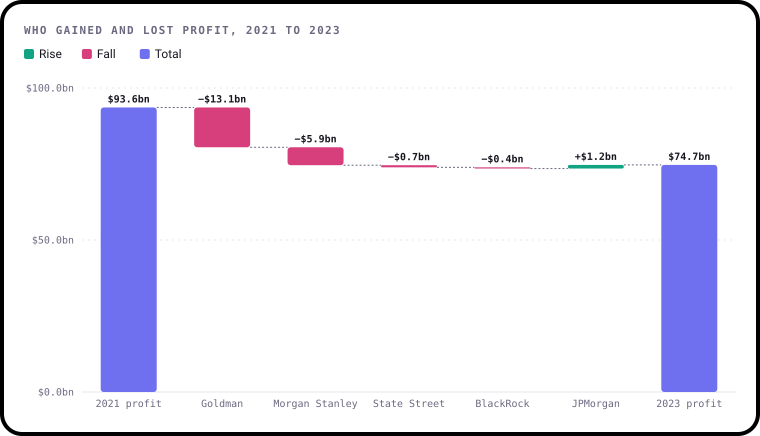

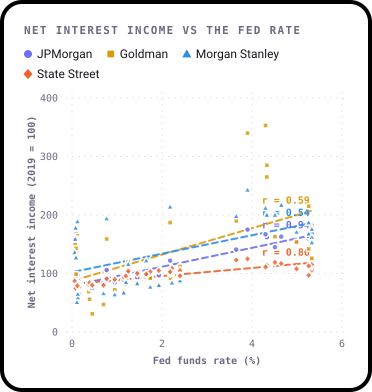

In [8]:
display(SVG(str(C.rates_waterfall("light"))))
display(SVG(str(C.nii_scatter("light"))))

**Reading it:** only JPMorgan, with the biggest deposit base, turned higher rates into much more interest income. Goldman and Morgan Stanley lost more from slower dealmaking than they gained.

## 8. Shocks

Profit in each shock window against the same quarters a year earlier (%).

In [9]:
s = F.shock_changes().pivot(index="firm", columns="shock_name", values="change_pct") * 100
s.index = [F.short_name(f) for f in s.index]
s[[x.name for x in F.SHOCKS]].round(0)

shock_name,2020 pandemic,2022 rate rises,2023 bank failures
BlackRock,-2.00,-12.00,0.00
Goldman,-66.00,-48.00,-35.00
JPMorgan,-60.00,-22.00,60.00
Morgan Stanley,6.00,-27.00,-16.00
State Street,21.00,3.00,-3.00


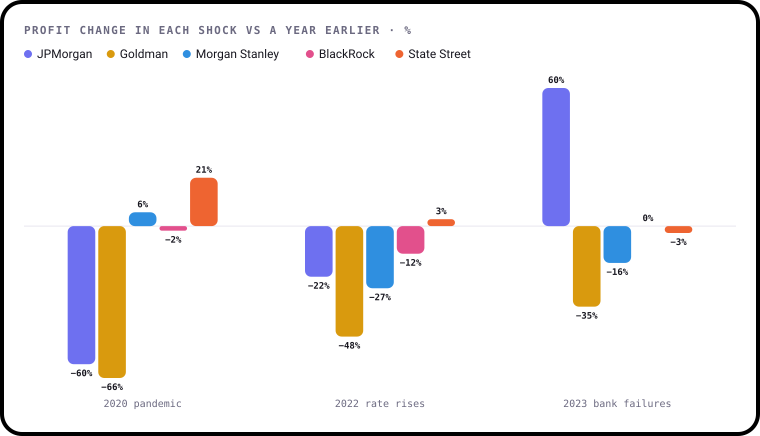

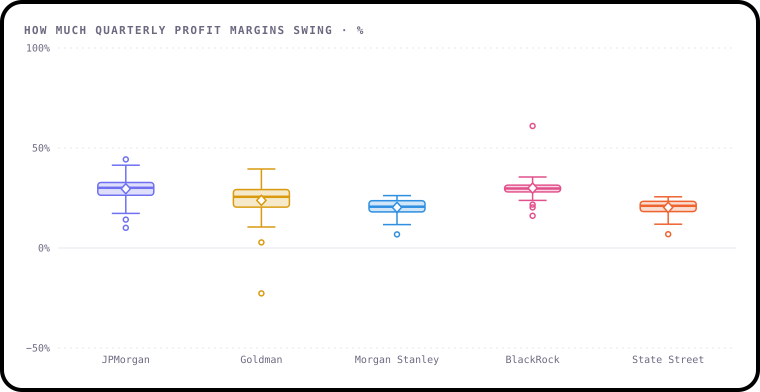

In [10]:
display(SVG(str(C.shock_bars("light"))))
display(SVG(str(C.margin_boxplot("light"))))

## The numbers the text quotes

Everything below is written to `findings/numbers.json` by `findings/build.py`.

In [11]:
pd.Series(F.headline_numbers()).to_frame("value").head(20)

,value
jpmorgan_revenue_2015_bn,93.54
jpmorgan_revenue_2025_bn,182.45
jpmorgan_profit_2015_bn,24.44
jpmorgan_profit_2025_bn,57.05
jpmorgan_profit_multiple,2.33
jpmorgan_revenue_multiple,1.95
jpmorgan_profit_change_2021_2023_pct,0.03
goldman_revenue_2015_bn,33.82
goldman_revenue_2025_bn,58.28
goldman_profit_2015_bn,6.08
